<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">


# Procesamiento de lenguaje natural
## Modelo de lenguaje con tokenización por caracteres

### Consigna
- Seleccionar un corpus de texto sobre el cual entrenar el modelo de lenguaje.
- Realizar el pre-procesamiento adecuado para tokenizar el corpus, estructurar el dataset y separar entre datos de entrenamiento y validación.
- Proponer arquitecturas de redes neuronales basadas en unidades recurrentes para implementar un modelo de lenguaje.
- Con el o los modelos que consideren adecuados, generar nuevas secuencias a partir de secuencias de contexto con las estrategias de greedy search y beam search determístico y estocástico. En este último caso observar el efecto de la temperatura en la generación de secuencias.


### Sugerencias
- Durante el entrenamiento, guiarse por el descenso de la perplejidad en los datos de validación para finalizar el entrenamiento. Para ello se provee un callback.
- Explorar utilizar SimpleRNN (celda de Elman), LSTM y GRU.
- rmsprop es el optimizador recomendado para la buena convergencia. No obstante se pueden explorar otros.

---
# Resolución

**Corpus:** la primera parte del *Quijote* (Project Gutenberg #2000): 990.347 caracteres en minúsculas, con 53 caracteres distintos. **Dataset:** contexto de 100 caracteres, ventanas de entrenamiento con paso 10 (89.115) y, para validación, el 10 % final del texto (990 bloques de 100).

| Modelo | Parámetros | Perplejidad de validación | Entrenamiento en CPU |
|---|---|---|---|
| Azar (el tamaño del vocabulario) / 5-grama de caracteres | — | 53 / 4,48 | — |
| `SimpleRNN(256)` | 92.981 | 4,80 | 5 min |
| `SimpleRNN(512)` | 316.981 | 5,58 | 8 min |
| `LSTM(256)` | 331.061 | 4,22 | 11 min |
| `GRU(256)` | 252.469 | 4,14 | 12 min |
| **2 × `GRU(256)` + `Dropout(0.2)`** | 647.221 | **3,97** | 27 min |

- **Arquitecturas:** con el mismo tamaño y las mismas épocas, las celdas con compuertas le ganan a la de Elman y son las únicas de una capa que superan al 5-grama. Duplicar el estado de la Elman no ayuda; apilar dos GRU con dropout en el medio, sí. Todos los modelos aprovechan unos 20 caracteres de contexto y ninguno saca provecho de más (punto 3.6).
- **Generación:** greedy y beam search determinista caen en loops ("los caballeros andantes de los caballeros andantes…"). La temperatura del beam search estocástico rompe los loops, pero el texto sigue hecho de frases muy frecuentes. Con muestreo puro, a temperatura 0,5 sale el texto más legible, a 1 aparecen palabras inventadas y a 1,5 se desarma.
- **Correcciones a la plantilla:** el armado de la validación (2.5), el orden del vocabulario (2.3), `X` e `y` con paso mayor que 1 (2.6), la entrada con `TimeDistributed` y el relleno con ceros (3.1), el callback de perplejidad (3.3 y 3.8), el sorteo con reposición del beam search estocástico (4.2) y la celda de Gradio (4.1).
- El notebook corre de punta a punta en unos 70 minutos en una CPU de 11 núcleos, sin GPU; casi todo es entrenamiento. En Colab conviene un entorno con GPU (el notebook la pide en sus metadatos, como la plantilla).

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # menos mensajes de TensorFlow al importarlo

import re
import sys
import time
import textwrap
import subprocess
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from numpy.lib.stride_tricks import sliding_window_view
from scipy.special import softmax

import tensorflow as tf
import keras
from keras import layers
from keras.utils import pad_sequences

keras.utils.set_random_seed(42)    # semillas de Python, NumPy y TensorFlow
tf.get_logger().setLevel('ERROR')  # oculta los avisos de retracing de tf.function al generar texto
sns.set_theme(style='whitegrid')
gpus = tf.config.list_physical_devices('GPU')
print(f'TensorFlow {tf.__version__} · Keras {keras.__version__} · {"GPU: " + gpus[0].name if gpus else "sin GPU: entrena en CPU"}')

TensorFlow 2.21.0 · Keras 3.15.1 · sin GPU: entrena en CPU


## 1. El corpus: *Don Quijote de la Mancha*

Uso **_El ingenioso hidalgo don Quijote de la Mancha_**, de Cervantes, en español: el libro **#2000 de Project Gutenberg** (texto plano UTF-8), el mismo corpus que el desafío 2. Es un texto largo, de un solo autor y con un estilo muy reconocible (arcaísmos como *desta* o *mesmo*, diálogos con raya, frases largas con muchas comas), así que es fácil ver si el modelo aprende algo de ese estilo.

La descarga prueba una lista de URLs en orden: primero el sitio de Gutenberg y, si no responde, dos espejos oficiales (`pglaf.org`). El sitio principal a veces devuelve error 503 a los pedidos automáticos; los espejos tienen el mismo archivo, aunque pueden ser lentos (un par de minutos).

In [2]:
# El libro #2000 de Project Gutenberg. Se prueban las URLs en orden hasta que una responda.
URLS = [
    'https://www.gutenberg.org/files/2000/2000-0.txt',
    'https://www.gutenberg.org/cache/epub/2000/pg2000.txt',
    'https://aleph.pglaf.org/2/0/0/2000/2000-0.txt',
    'https://gutenberg.pglaf.org/2/0/0/2000/2000-0.txt',
]


def descargar(urls):
    for url in urls:
        try:
            t0 = time.perf_counter()
            with urllib.request.urlopen(url, timeout=60) as respuesta:
                texto = respuesta.read().decode('utf-8')
            print(f'OK  {url} · {len(texto):,} caracteres en {time.perf_counter() - t0:.0f} s')
            return texto
        except Exception as e:
            print(f'--  {url} · {e}')
    raise RuntimeError('No se pudo descargar el libro de ninguna de las URLs')


raw_text = descargar(URLS)

--  https://www.gutenberg.org/files/2000/2000-0.txt · HTTP Error 503: Service Unavailable


--  https://www.gutenberg.org/cache/epub/2000/pg2000.txt · HTTP Error 503: Service Unavailable


OK  https://aleph.pglaf.org/2/0/0/2000/2000-0.txt · 2,110,809 caracteres en 68 s


### Limpieza y subconjunto

- **Encabezado y pie de Gutenberg:** corto lo que está fuera de las marcas `*** START OF …` y `*** END OF …` (licencia, créditos, etc.).
- **Solo la primera parte (1605), capítulos I a LII:** el libro completo tiene unos 2,1 millones de caracteres y en esta máquina (CPU, sin GPU) entrenar varias arquitecturas sobre todo eso no entra en un tiempo razonable. La primera parte es una unidad natural, tiene ≈ 1 millón de caracteres y alcanza para que un modelo por caracteres aprenda ortografía, palabras frecuentes y algo de sintaxis. Arranco en el capítulo primero ("En un lugar de la Mancha…") y dejo afuera los preliminares (tasa, dedicatoria, prólogo y los poemas burlescos), que son de otro registro.

In [3]:
texto = raw_text.replace('\r\n', '\n')
libro = texto[texto.index('\n', texto.index('*** START OF')) + 1:texto.index('*** END OF')]

# Primera parte: desde el capítulo primero hasta el "Finis" que la cierra (justo antes de la segunda parte).
parte1 = libro[libro.index('Capítulo primero.'):libro.index('\nFinis\n')]
assert 900_000 < len(parte1) < 1_100_000, 'No se encontró bien la primera parte: revisar las marcas del texto descargado'

print(f'Libro sin encabezado ni pie de Gutenberg: {len(libro):,} caracteres')
print(f'Primera parte (capítulos I a LII): {len(parte1):,} caracteres ({len(parte1) / len(libro):.0%} del libro)')
print('\nAsí viene el texto, cortado en líneas de ~75 caracteres:\n')
print(parte1[:420])

Libro sin encabezado ni pie de Gutenberg: 2,110,711 caracteres
Primera parte (capítulos I a LII): 992,534 caracteres (47% del libro)

Así viene el texto, cortado en líneas de ~75 caracteres:

Capítulo primero. Que trata de la condición y ejercicio del famoso hidalgo
don Quijote de la Mancha

En un lugar de la Mancha, de cuyo nombre no quiero acordarme, no ha mucho
tiempo que vivía un hidalgo de los de lanza en astillero, adarga antigua,
rocín flaco y galgo corredor. Una olla de algo más vaca que carnero,
salpicón las más noches, duelos y quebrantos los sábados, lantejas los
viernes, algún palomino de añad


## 2. Preprocesamiento

### 2.1 Normalización

- **Saltos de línea:** el archivo de Gutenberg corta las líneas cada ~75 caracteres, en cualquier lugar de la oración. Ese salto no es del idioma sino de la edición: si lo dejo, el modelo gasta capacidad en aprender a contar caracteres para poner un `\n` cada tanto. Uno las líneas de cada párrafo con un espacio y dejo **un `\n` entre párrafos**, que sí aporta estructura: separa la narración de cada intervención de un diálogo.
- **Minúsculas:** igual que la plantilla (y que su `generate_seq`, que pasa la semilla a minúsculas). Las mayúsculas solo aparecen al principio de oración y en nombres propios; sin ellas el vocabulario baja de 81 a 53 caracteres y un modelo chico concentra su capacidad en lo que importa: ortografía, palabras y puntuación. La contra es que el texto generado no tiene mayúsculas.
- **Números, puntuación y espacios: se dejan**, como recomendó la docente. Entran al vocabulario como cualquier carácter, y así el modelo aprende a poner comas, puntos, signos de pregunta y la raya de los diálogos. (En la primera parte no hay dígitos: Cervantes escribe los números con letras.)
- Colapso los espacios repetidos en uno.

In [4]:
def normalizar(texto):
    """Une las líneas de cada párrafo con un espacio, deja un salto de línea entre párrafos y pasa a minúsculas."""
    parrafos = (' '.join(p.split()) for p in re.split(r'\n\s*\n', texto))
    return '\n'.join(p for p in parrafos if p).lower()


article_text = normalizar(parte1)
print(f'Texto normalizado: {len(article_text):,} caracteres · {article_text.count(chr(10)) + 1:,} párrafos\n')
for linea in article_text[:900].split('\n'):
    print(textwrap.fill(linea, 110))

Texto normalizado: 990,347 caracteres · 2,034 párrafos

capítulo primero. que trata de la condición y ejercicio del famoso hidalgo don quijote de la mancha
en un lugar de la mancha, de cuyo nombre no quiero acordarme, no ha mucho tiempo que vivía un hidalgo de los
de lanza en astillero, adarga antigua, rocín flaco y galgo corredor. una olla de algo más vaca que carnero,
salpicón las más noches, duelos y quebrantos los sábados, lantejas los viernes, algún palomino de añadidura
los domingos, consumían las tres partes de su hacienda. el resto della concluían sayo de velarte, calzas de
velludo para las fiestas, con sus pantuflos de lo mesmo, y los días de entresemana se honraba con su vellorí
de lo más fino. tenía en su casa una ama que pasaba de los cuarenta, y una sobrina que no llegaba a los
veinte, y un mozo de campo y plaza, que así ensillaba el rocín como tomaba la podadera. frisaba la edad de
nuestro hidalgo con los cincuenta años; era de


### 2.2 Tamaño del contexto

Como dice la plantilla, en un modelo por caracteres todo el corpus puede tratarse como un único documento, y el contexto se elige con libertad. Tiene que ser bastante más largo que con palabras, porque cada paso es un carácter: para ver la misma cantidad de texto hacen falta 5 o 6 pasos por palabra.

Miro cuánto miden las palabras, las oraciones y los párrafos, en caracteres:

Palabras: 181,155 · largo medio 4.3 letras (≈ 5.5 caracteres por palabra contando espacios y puntuación)
Oraciones (cortando en . ! ? ; :): 7,371 · mediana 115 caracteres, percentil 75: 179, percentil 90: 254
Párrafos: mediana 270 caracteres


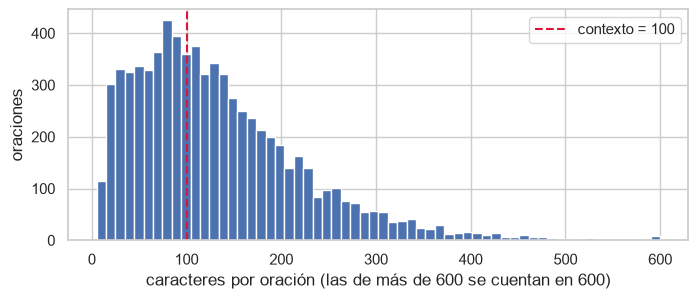

In [5]:
palabras = re.findall(r'\w+', article_text)
oraciones = [o for o in re.split(r'(?<=[.!?;:])\s+', article_text) if o]
largo_oraciones = np.array([len(o) for o in oraciones])
largo_parrafos = np.array([len(p) for p in article_text.split('\n')])

print(f'Palabras: {len(palabras):,} · largo medio {np.mean([len(p) for p in palabras]):.1f} letras '
      f'(≈ {len(article_text) / len(palabras):.1f} caracteres por palabra contando espacios y puntuación)')
print(f'Oraciones (cortando en . ! ? ; :): {len(oraciones):,} · mediana {np.median(largo_oraciones):.0f} caracteres, '
      f'percentil 75: {np.percentile(largo_oraciones, 75):.0f}, percentil 90: {np.percentile(largo_oraciones, 90):.0f}')
print(f'Párrafos: mediana {np.median(largo_parrafos):.0f} caracteres')

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(np.clip(largo_oraciones, 0, 600), bins=60)
ax.axvline(100, color='crimson', ls='--', label='contexto = 100')
ax.set(xlabel='caracteres por oración (las de más de 600 se cuentan en 600)', ylabel='oraciones')
ax.legend()
plt.show()

Me quedo con el **contexto de 100 caracteres de la plantilla**:

- 100 caracteres son ≈ 18 palabras, más o menos una oración (la mediana es de 115 caracteres) o una cláusula larga. Alcanza para que el modelo tenga a la vista la palabra en curso, las anteriores y la puntuación reciente (si hay un diálogo abierto, si viene una enumeración).
- El contexto también es el **largo del *backpropagation through time***: cada ventana se procesa desde un estado en cero, así que el modelo no puede aprender dependencias de más de 100 caracteres. Alargarlo haría más largas las secuencias del BPTT, donde la SimpleRNN ya tiene problemas (clase 3), y con el mismo paso aumentaría el cómputo por época.
- En el punto 3.6 mido cuánto de ese contexto usa realmente cada arquitectura: la perplejidad según la posición dentro de la ventana.

In [6]:
# seleccionamos el tamaño de contexto
max_context_size = 100

### 2.3 Vocabulario

El vocabulario es el conjunto de caracteres del texto. Corrijo un detalle de la plantilla: `set(article_text)` **no tiene un orden fijo**. Python randomiza el hash de los `str` en cada sesión (`PYTHONHASHSEED`), así que el orden del `set` y con él `char2idx` pueden cambiar entre una ejecución y otra; un modelo guardado en una sesión le asignaría sus salidas a otros caracteres en la siguiente. Con `sorted(set(...))` el mapeo queda fijo. La demostración corre dos intérpretes con semillas de hash distintas:

In [7]:
for semilla in ('1', '2'):
    orden = subprocess.run([sys.executable, '-c', 'print("".join(set("en un lugar de la mancha")))'],
                           capture_output=True, text=True, env={**os.environ, 'PYTHONHASHSEED': semilla}).stdout.strip()
    print(f'PYTHONHASHSEED={semilla}: set → {orden!r}')

PYTHONHASHSEED=1: set → 'dgumrnela hc'
PYTHONHASHSEED=2: set → 'lhgn ecmdrau'


In [8]:
# en este caso el vocabulario es el conjunto único de caracteres que existe en todo el texto, ordenado
chars_vocab = sorted(set(article_text))
vocab_size = len(chars_vocab)

# Construimos los dicionarios que asignan índices a caracteres y viceversa.
# El diccionario `char2idx` servirá como tokenizador.
char2idx = {k: v for v, k in enumerate(chars_vocab)}
idx2char = {v: k for k, v in char2idx.items()}

frecuencias = Counter(article_text)
print(f'{vocab_size} caracteres: {"".join(chars_vocab)!r}')
print('Los más frecuentes:', ' · '.join(f'{c!r} {n:,}' for c, n in frecuencias.most_common(8)))
print('Los más raros:     ', ' · '.join(f'{c!r} {n}' for c, n in sorted(frecuencias.items(), key=lambda x: x[1])[:8]))

53 caracteres: '\n !"\'(),-.:;?]abcdefghijlmnopqrstuvwxyz¡«»¿àáéíïñóúü—'
Los más frecuentes: ' ' 180,280 · 'e' 105,702 · 'a' 93,073 · 'o' 72,030 · 's' 58,472 · 'n' 50,854 · 'r' 47,596 · 'l' 42,750
Los más raros:      'w' 1 · ']' 1 · 'à' 1 · 'ï' 3 · '-' 9 · 'ü' 34 · '«' 35 · '(' 40


- Quedan **53 caracteres**: el espacio, el salto de párrafo, las letras (con tildes, `ñ` y `ü`), los signos de puntuación del español (`¿ ¡ « » —`) y unos pocos raros. El índice 0 es el salto de línea (`\n`), el primero en orden.
- El espacio es el carácter más frecuente (18 % del texto), seguido de las vocales `e` y `a`.
- Hay caracteres casi inexistentes (`w`, `]`, `à`, `ï`: entre 1 y 3 apariciones). Los dejo: no molestan, y el modelo aprende que casi nunca aparecen.

### 2.4 Tokenización

Cada carácter se reemplaza por su índice. `encode` y `decode` (de la plantilla) van a servir en todo el notebook; `encode` ahora pasa a minúsculas y saltea los caracteres que no están en el vocabulario (la de la plantilla fallaba con una mayúscula).

In [9]:
def encode(text):
    """Texto → índices. Pasa a minúsculas y saltea los caracteres fuera del vocabulario."""
    return np.array([char2idx[ch] for ch in text.lower() if ch in char2idx], dtype=np.int32)


def decode(seq):
    """Índices → texto."""
    return ''.join(idx2char[int(i)] for i in seq)


# tokenizamos el texto completo
tokenized_text = encode(article_text)
print(tokenized_text[:24])
print(repr(decode(tokenized_text[:24])))

[16 14 28 46 32 33 24 27  1 28 30 22 25 18 30 27  9  1 29 33 18  1 32 30]
'capítulo primero. que tr'


### 2.5 Entrenamiento y validación

Como en la plantilla, la validación es el **10 % final del texto, en un solo bloque**: el final del capítulo XLVI y los capítulos XLVII a LII (don Quijote enjaulado en el carro de bueyes, el canónigo, el cabrero y los sonetos y epitafios de los académicos de la Argamasilla). No conviene sortear ventanas al azar: como se solapan, casi todo el texto de una ventana de validación estaría también en alguna de entrenamiento y la perplejidad saldría optimista. Con un bloque contiguo, el modelo se evalúa con texto que no vio, aunque del mismo libro.

In [10]:
# separaremos el dataset entre entrenamiento y validación.
# `p_val` será la proporción del corpus que se reservará para validación
# `num_val` es la cantidad de secuencias de tamaño `max_context_size` que se usará en validación
p_val = 0.1
num_val = int(np.ceil(len(tokenized_text) * p_val / max_context_size))

# separamos la porción de texto utilizada en entrenamiento de la de validación.
train_text = tokenized_text[:-num_val * max_context_size]
val_text = tokenized_text[-num_val * max_context_size:]
print(f'Entrenamiento: {len(train_text):,} caracteres · validación: {len(val_text):,} caracteres ({num_val} bloques de {max_context_size})')
print('La validación empieza en:', repr(decode(val_text[:120])))

Entrenamiento: 891,247 caracteres · validación: 99,100 caracteres (991 bloques de 100)
La validación empieza en: 'os servicios, sino a la posibilidad mía.\nsancho panza se le inclinó con mucho comedimiento, y le besó entrambas las mano'


**El armado de las secuencias de validación de la plantilla está mal.** Usa `val_text[init*max_context_size:init*(max_context_size+1)]`: el bloque `init` empieza en `100·init` pero termina en `101·init`, así que mide `init` caracteres y no 100. Las secuencias salen de largo 0, 1, 2, 3…; desde la 101 se solapan entre sí, y al final se recortan contra el borde del texto:

In [11]:
val_plantilla = [val_text[init * max_context_size:init * (max_context_size + 1)] for init in range(num_val)]
largos = [len(s) for s in val_plantilla]
print('Largos con la plantilla: ', largos[:8], '…', largos[-4:])
print(f'Predicciones que haría el callback de la plantilla: {sum(max(n - 1, 0) for n in largos):,}')

# Corregido: bloques consecutivos de max_context_size caracteres, sin solapamiento.
tokenized_sentences_val = [val_text[init * max_context_size:(init + 1) * max_context_size] for init in range(num_val)]
print('Largos corregidos:       ', sorted(set(len(s) for s in tokenized_sentences_val)))
print(f'Predicciones con la corrección: {sum(len(s) - 1 for s in tokenized_sentences_val):,}')

Largos con la plantilla:  [0, 1, 2, 3, 4, 5, 6, 7] … [400, 300, 200, 100]
Predicciones que haría el callback de la plantilla: 485,181
Largos corregidos:        [100]
Predicciones con la corrección: 98,109


Con el error, el callback de la plantilla haría casi **cinco veces más predicciones** (cada una sobre una entrada de 100 caracteres) y sobre un conjunto sesgado: el principio de la validación casi no se evalúa (los primeros bloques miden 1, 2, 3… caracteres) y la zona del medio se cuenta varias veces. Con la corrección, cada carácter de validación se predice una vez.

### 2.6 Ventanas de entrenamiento y paso (*stride*)

La plantilla arma una ventana de 100 caracteres que empieza en **cada** carácter del texto (paso 1). Con 891.000 caracteres de entrenamiento serían 891.000 ventanas por época, casi idénticas entre sí: dos ventanas consecutivas comparten 99 de sus 100 caracteres. Medí con un script aparte que una `LSTM(256)` entrena a unos 176.000 caracteres por segundo en esta CPU (con batch de 256): con paso 1, **una sola época tardaría ~8,5 minutos** (89 millones de caracteres).

Uso **paso 10**: 89.000 ventanas por época, ~10 veces menos cómputo. No se pierde texto: cada carácter sigue apareciendo como target en 10 ventanas por época, cada vez en otra posición (con más o menos contexto previo). Lo que se descarta son ventanas redundantes, que aportan casi el mismo gradiente; si hace falta más entrenamiento, se agregan épocas.

**La forma de armar `X` e `y` también cambia.** La plantilla hace `X = ventanas[:-1]` e `y = ventanas[1:]`: el target de cada ventana es la ventana siguiente, que con paso 1 es la misma secuencia corrida un carácter. Con paso 10, la ventana siguiente está corrida **10** caracteres y el target quedaría mal. Por eso armo ventanas de 101 caracteres y separo `X = ventana[:-1]` e `y = ventana[1:]`, que funciona con cualquier paso. La validación usa paso 100 (bloques sin solapamiento, los mismos de `tokenized_sentences_val` más el carácter siguiente como último target).

In [12]:
def ventanas(tokens, largo, paso):
    """Ventanas de largo+1 tokens que empiezan cada `paso` tokens: X es la ventana sin el último, y sin el primero."""
    W = sliding_window_view(tokens, largo + 1)[::paso]
    return W[:, :-1].copy(), W[:, 1:].copy()


paso_train = 10
X, y = ventanas(train_text, max_context_size, paso_train)
X_val, y_val = ventanas(val_text, max_context_size, max_context_size)
assert (X[:, 1:] == y[:, :-1]).all() and (X_val[:, 1:] == y_val[:, :-1]).all()  # y es X corrida un lugar

print(f'X: {X.shape} · y: {y.shape} · X_val: {X_val.shape} · y_val: {y_val.shape}')
print(f'X[0] = {decode(X[0][:60])!r}…')
print(f'y[0] = {decode(y[0][:60])!r}…  ← la misma secuencia corrida un carácter')
print(f'X[1] = {decode(X[1][:60])!r}…  ← la ventana siguiente empieza {paso_train} caracteres después')

X: (89115, 100) · y: (89115, 100) · X_val: (990, 100) · y_val: (990, 100)
X[0] = 'capítulo primero. que trata de la condición y ejercicio del '…
y[0] = 'apítulo primero. que trata de la condición y ejercicio del f'…  ← la misma secuencia corrida un carácter
X[1] = 'rimero. que trata de la condición y ejercicio del famoso hid'…  ← la ventana siguiente empieza 10 caracteres después


Nótese que estamos estructurando el problema de aprendizaje como *many-to-many*:

Entrada: secuencia de tokens [$x_0$, $x_1$, ..., $x_N$]

Target: secuencia de tokens [$x_1$, $x_2$, ..., $x_{N+1}$]

De manera que la red tiene que aprender que su salida deben ser los tokens desplazados en una posición y un nuevo token predicho (el N+1).

La ventaja de estructurar el aprendizaje de esta manera es que para cada token de target se propaga una señal de gradiente por el grafo de cómputo recurrente, que es mejor que estructurar el problema como *many-to-one* en donde sólo una señal de gradiente se propaga.

Con 89.115 ventanas de 100 caracteres, cada época tiene ≈ 8,9 millones de targets.

## 3. Arquitecturas recurrentes

### 3.1 La entrada de la plantilla en Keras 3

La plantilla pasa los índices a one-hot con `TimeDistributed(CategoryEncoding(output_mode="one_hot"))` e `input_shape=(None, 1)`: espera una dimensión final de tamaño 1, pero `X` es de forma `(N, 100)`. Verifico qué pasa en Keras 3 con el modelo de la plantilla: un `fit` corto y dos `predict` con secuencias de distinto largo.

In [13]:
modelo_plantilla = keras.Sequential([
    layers.Input(shape=(None, 1)),  # equivale al input_shape=(None, 1) de la plantilla
    layers.TimeDistributed(layers.CategoryEncoding(num_tokens=vocab_size, output_mode='one_hot')),
    layers.SimpleRNN(200, return_sequences=True, dropout=0.1, recurrent_dropout=0.1),
    layers.Dense(vocab_size, activation='softmax'),
])
modelo_plantilla.compile(loss='sparse_categorical_crossentropy', optimizer='rmsprop')
print('Entrada que espera el modelo:', modelo_plantilla.input_shape)
h = modelo_plantilla.fit(X[:1024], y[:1024], batch_size=256, epochs=1, verbose=0)
print(f'fit con X de forma {X[:1024].shape}: anda (loss {h.history["loss"][0]:.2f})')
for largo in (max_context_size, 13):
    salida = modelo_plantilla.predict(X[:2, :largo], verbose=0)
    print(f'predict con forma {X[:2, :largo].shape} → salida {salida.shape}')
print(f'llamada directa model(x) con forma {X[:2, :13].shape} → salida {tuple(modelo_plantilla(X[:2, :13]).shape)}')

Entrada que espera el modelo: (None, None, 1)


fit con X de forma (1024, 100): anda (loss 3.56)


predict con forma (2, 100) → salida (2, 100, 53)
predict con forma (2, 13) → salida (2, 2, 53)
llamada directa model(x) con forma (2, 13) → salida (2, 13, 53)


- **Con `X` de forma `(N, 100)` anda:** Keras 3 compara el rango de los datos con el de la entrada y agrega solo la dimensión final de tamaño 1. `fit` y `predict` con secuencias de 100 caracteres dan las formas correctas.
- **Pero `predict` falla en silencio si cambia el largo de la secuencia.** Después de una llamada con 100 caracteres, la entrada de 13 devuelve una salida de forma `(2, 2, 53)` en lugar de `(2, 13, 53)`: la dimensión del tiempo sale igual al batch. Es un problema de `TimeDistributed` cuando `predict` vuelve a compilar la función para un largo distinto (la llamada directa `model(x)` da bien). La plantilla no lo sufre porque rellena todas las entradas hasta 100 con `pad_sequences`.
- **Ese relleno es otro problema:** `pad_sequences` rellena con 0, y acá el 0 no es un token de *padding* sino un carácter real (el `\n` con el vocabulario ordenado; con el `set` de la plantilla, uno cualquiera). Una semilla de 13 caracteres se convierte en 87 saltos de línea seguidos de la semilla, algo que el modelo nunca vio al entrenar.

**Solución:** reemplazo la entrada por un `Embedding` **congelado con la matriz identidad**. La fila *i* de la identidad es el vector one-hot del carácter *i*, así que es exactamente el mismo one-hot de la plantilla, sin parámetros entrenables (no es un embedding aprendido: los caracteres no tienen significado semántico, como se dijo en clase). Funciona con cualquier largo de secuencia, y entonces genero **sin relleno**: la red recurrente acepta secuencias de cualquier largo, y una semilla corta, procesada desde el estado en cero, es lo mismo que vio en entrenamiento al principio de cada ventana.

### 3.2 Los modelos

Todas siguen el esquema de la plantilla: one-hot → capa(s) recurrente(s) con `return_sequences=True` (many-to-many, una salida por carácter) → `Dense(vocab_size, softmax)`. Comparo:

| Modelo | Por qué |
|---|---|
| `SimpleRNN(256)` | La celda de Elman, la base de la clase 3 |
| `GRU(256)` | Compuertas de reset y update: ~3 veces los parámetros de Elman |
| `LSTM(256)` | Memoria de largo plazo C y tres compuertas: ~4 veces los parámetros |
| `SimpleRNN(512)` | Control: una Elman con casi tantos parámetros como la `LSTM(256)` (317.000 contra 331.000), para ver si la diferencia es de **capacidad** o de la **celda** |
| 2 capas + `Dropout(0.2)` | La mejor celda entre GRU y LSTM, apilada, con dropout en el medio (como sugirió la docente y como el modelo de la clase) |

Mismo presupuesto para todas: los mismos datos, `rmsprop` con *learning rate* 0,003, batch de 256 y como máximo 12 épocas, con early stopping si la perplejidad de validación no mejora en 3. Las tres primeras tienen el mismo tamaño de estado (256), como en el *adding problem* de la clase 3. El *learning rate* y el batch salen de pruebas previas (punto 3.7).

El dropout va como capa `Dropout` **entre** las capas recurrentes y no como `recurrent_dropout`, que en la GPU de Colab impide usar la implementación de cuDNN y vuelve el entrenamiento varias veces más lento. Aun en esta CPU, sin cuDNN, una `LSTM(256)` con `recurrent_dropout=0.1` entrenó a 83.000 caracteres por segundo, contra 176.000 sin él: **el doble de tiempo**. Las variantes de una capa no llevan dropout, para comparar las celdas solas.

In [14]:
UNIDADES, BATCH, LR = 256, 256, 3e-3
EPOCAS, PACIENCIA = 12, 3


def crear_modelo(celda, unidades=UNIDADES, capas=1, dropout=0.0):
    model = keras.Sequential()
    model.add(layers.Input(shape=(None,), dtype='int32'))
    # One-hot sin parámetros entrenables: la fila i de la identidad es el vector one-hot del carácter i.
    model.add(layers.Embedding(vocab_size, vocab_size, embeddings_initializer='identity', trainable=False))
    for i in range(capas):
        model.add(celda(unidades, return_sequences=True))  # many-to-many: una salida por carácter
        if dropout and i < capas - 1:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(vocab_size, activation='softmax'))
    model.compile(loss='sparse_categorical_crossentropy', optimizer=keras.optimizers.RMSprop(learning_rate=LR))
    return model


def parametros(model):
    """Parámetros entrenables (no cuenta la matriz identidad del one-hot)."""
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))


crear_modelo(layers.LSTM).summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, None, 53)       │         2,809 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, None, 256)      │       317,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, None, 53)       │        13,621 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 333,870 (1.27 MB)

 Trainable params: 331,061 (1.26 MB)

 Non-trainable params: 2,809 (10.97 KB)

`LSTM(256)` con 53 entradas: 4 · 256 · (256 + 53 + 1) = 317.440 parámetros (las cuatro subceldas de la clase 3), más 256 · 53 + 53 = 13.621 de la densa. Los 2.809 no entrenables son la identidad de 53 × 53.

### 3.3 La perplejidad

La perplejidad es la exponencial de la entropía cruzada media: "entre cuántos caracteres está dudando" el modelo en cada paso.

$$\text{PPL} = \exp\left(-\frac{1}{N}\sum_{t=1}^{N} \log P(x_t \mid x_1, \dots, x_{t-1})\right)$$

**Valores de referencia.** Un modelo que no sabe nada reparte la probabilidad por igual y tiene perplejidad igual al vocabulario, **53** (con palabras, en el ejemplo de Borges, era ≈ 15.000: no se pueden comparar). Para tener un piso más exigente, calculo la perplejidad en validación de modelos de **n-gramas de caracteres**, que solo cuentan qué carácter sigue a los n − 1 anteriores en el train (con suavizado aditivo, α = 0,1):

In [15]:
def perplejidad_ngramas(n, alpha=0.1):
    """Perplejidad en validación de un modelo de n-gramas de caracteres contado en train (suavizado aditivo)."""
    tr, va = train_text.tolist(), val_text.tolist()
    contexto, completo = Counter(), Counter()
    for i in range(n - 1, len(tr)):
        contexto[tuple(tr[i - n + 1:i])] += 1
        completo[tuple(tr[i - n + 1:i + 1])] += 1
    logp = [np.log((completo[tuple(va[i - n + 1:i + 1])] + alpha) / (contexto[tuple(va[i - n + 1:i])] + alpha * vocab_size))
            for i in range(n - 1, len(va))]
    return np.exp(-np.mean(logp))


referencias = {'uniforme': vocab_size, **{f'{n}-grama': perplejidad_ngramas(n) for n in range(1, 6)}}
pd.Series(referencias, name='perplejidad en validación').round(2).to_frame().T

,uniforme,1-grama,2-grama,3-grama,4-grama,5-grama
perplejidad en validación,53.0,18.67,9.16,6.52,4.94,4.48


- Saber solo la frecuencia de cada carácter (1-grama) ya baja de 53 a 18,7. Con 4 caracteres de contexto (5-grama) se llega a 4,48.
- El 5-grama es un rival serio: con 4 caracteres a la vista ya completa casi cualquier palabra. Una red recurrente tiene que superarlo usando contexto más largo y generalizando a combinaciones que no vio contadas.

**El callback.** El de la plantilla calcula la perplejidad "desde cero": para cada bloque de validación arma los 99 prefijos, los rellena con ceros hasta 100 y hace una predicción por prefijo. Aun con la validación corregida son **98.109 predicciones de 100 pasos por época**, cuando una sola pasada por los 990 bloques (many-to-many) ya da la probabilidad de cada carácter dado todo lo anterior. Uso la **versión simplificada del notebook de la clase**: Keras calcula la entropía cruzada de validación (`val_loss`) con `validation_data` y el callback le aplica la exponencial. Le agrego lo que hacía el de la plantilla: el early stopping con paciencia y quedarse con el mejor modelo. Los mejores pesos quedan en memoria, sin escribir `my_model.keras`. En el punto 3.8 comparo las dos cuentas sobre el mejor modelo.

In [16]:
class PplCallback(keras.callbacks.Callback):
    """Perplejidad de validación = exp(entropía cruzada de validación que calcula Keras).

    Corta el entrenamiento si no mejora en `patience` épocas (early stopping) y, al terminar, deja el modelo
    con los pesos de la mejor época (en memoria: no guarda archivos).
    """

    def __init__(self, patience=PACIENCIA):
        super().__init__()
        self.patience = patience

    def on_train_begin(self, logs=None):
        self.history_ppl, self.min_score, self.best_epoch, self.wait = [], np.inf, 0, 0
        self.t0 = time.perf_counter()

    def on_epoch_begin(self, epoch, logs=None):
        self.t_epoch = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        ppl_train, ppl_val = np.exp(logs['loss']), np.exp(logs['val_loss'])
        self.history_ppl.append((ppl_train, ppl_val))
        mejora = ppl_val < self.min_score
        if mejora:
            self.min_score, self.best_epoch, self.wait = ppl_val, epoch + 1, 0
            self.best_weights = self.model.get_weights()
        else:
            self.wait += 1
            if self.wait >= self.patience:
                self.model.stop_training = True
        print(f'  época {epoch + 1:>2} · {time.perf_counter() - self.t_epoch:3.0f} s · perplejidad '
              f'train {ppl_train:6.3f} · validación {ppl_val:6.3f}{"  ← mejor" if mejora else ""}')

    def on_train_end(self, logs=None):
        self.model.set_weights(self.best_weights)
        self.train_time = time.perf_counter() - self.t0

La perplejidad de train es el promedio durante la época, con los pesos cambiando; la de validación se mide al final. Por eso en las primeras épocas la de train sale más alta que la de validación.

### 3.4 Entrenamiento

In [17]:
resultados = {}


def entrenar(nombre, model):
    """Entrena con early stopping por perplejidad de validación y guarda el modelo y su historia."""
    print(f'{nombre}: {parametros(model):,} parámetros entrenables')
    cb = PplCallback()
    model.fit(X, y, validation_data=(X_val, y_val), epochs=EPOCAS, batch_size=BATCH, callbacks=[cb], verbose=0)
    print(f'  → mejor perplejidad de validación {cb.min_score:.3f} (época {cb.best_epoch}) · {cb.train_time / 60:.1f} min')
    resultados[nombre] = {'model': model, 'cb': cb}


entrenar('SimpleRNN(256)', crear_modelo(layers.SimpleRNN))

SimpleRNN(256): 92,981 parámetros entrenables


  época  1 ·  24 s · perplejidad train  9.287 · validación  7.347  ← mejor


  época  2 ·  24 s · perplejidad train  5.717 · validación  5.913  ← mejor


  época  3 ·  24 s · perplejidad train  4.829 · validación  5.492  ← mejor


  época  4 ·  24 s · perplejidad train  4.437 · validación  5.188  ← mejor


  época  5 ·  24 s · perplejidad train  4.223 · validación  5.112  ← mejor


... (3 outputs left out)

  época  9 ·  24 s · perplejidad train  3.867 · validación  4.887  ← mejor


  época 10 ·  24 s · perplejidad train  3.823 · validación  4.868  ← mejor


  época 11 ·  24 s · perplejidad train  3.787 · validación  4.823  ← mejor


  época 12 ·  24 s · perplejidad train  3.757 · validación  4.795  ← mejor
  → mejor perplejidad de validación 4.795 (época 12) · 4.7 min


In [18]:
entrenar('GRU(256)', crear_modelo(layers.GRU))

GRU(256): 252,469 parámetros entrenables


  época  1 ·  60 s · perplejidad train  8.536 · validación  6.687  ← mejor


  época  2 ·  63 s · perplejidad train  5.520 · validación  5.217  ← mejor


  época  3 ·  60 s · perplejidad train  4.441 · validación  4.603  ← mejor


  época  4 ·  64 s · perplejidad train  3.949 · validación  4.328  ← mejor


  época  5 ·  63 s · perplejidad train  3.682 · validación  4.214  ← mejor


... (3 outputs left out)

  época  9 ·  60 s · perplejidad train  3.200 · validación  4.138  ← mejor


  época 10 ·  60 s · perplejidad train  3.131 · validación  4.196


  época 11 ·  66 s · perplejidad train  3.071 · validación  4.257


  época 12 ·  61 s · perplejidad train  3.019 · validación  4.332
  → mejor perplejidad de validación 4.138 (época 9) · 12.3 min


In [19]:
entrenar('LSTM(256)', crear_modelo(layers.LSTM))

LSTM(256): 331,061 parámetros entrenables


  época  1 ·  54 s · perplejidad train 10.769 · validación  7.671  ← mejor


  época  2 ·  53 s · perplejidad train  6.480 · validación  6.068  ← mejor


  época  3 ·  53 s · perplejidad train  5.374 · validación  5.353  ← mejor


  época  4 ·  53 s · perplejidad train  4.772 · validación  4.979  ← mejor


  época  5 ·  53 s · perplejidad train  4.403 · validación  4.702  ← mejor


... (3 outputs left out)

  época  9 ·  53 s · perplejidad train  3.681 · validación  4.274  ← mejor


  época 10 ·  53 s · perplejidad train  3.581 · validación  4.258  ← mejor


  época 11 ·  53 s · perplejidad train  3.496 · validación  4.253  ← mejor


  época 12 ·  53 s · perplejidad train  3.421 · validación  4.222  ← mejor
  → mejor perplejidad de validación 4.222 (época 12) · 10.7 min


In [20]:
entrenar('SimpleRNN(512)', crear_modelo(layers.SimpleRNN, unidades=512))

SimpleRNN(512): 316,981 parámetros entrenables


  época  1 ·  41 s · perplejidad train 24.559 · validación 15.972  ← mejor


  época  2 ·  42 s · perplejidad train 12.477 · validación 10.477  ← mejor


  época  3 ·  41 s · perplejidad train  9.012 · validación  9.936  ← mejor


  época  4 ·  41 s · perplejidad train  7.898 · validación  7.969  ← mejor


  época  5 ·  41 s · perplejidad train  7.060 · validación  7.203  ← mejor


... (3 outputs left out)

  época  9 ·  41 s · perplejidad train  5.538 · validación  5.900  ← mejor


  época 10 ·  41 s · perplejidad train  5.302 · validación  5.670  ← mejor


  época 11 ·  41 s · perplejidad train  5.078 · validación  5.879


  época 12 ·  41 s · perplejidad train  4.895 · validación  5.583  ← mejor
  → mejor perplejidad de validación 5.583 (época 12) · 8.3 min


In [21]:
# La variante apilada usa la mejor celda con compuertas.
celda_2c = 'GRU' if resultados['GRU(256)']['cb'].min_score < resultados['LSTM(256)']['cb'].min_score else 'LSTM'
entrenar(f'2 × {celda_2c}(256) + Dropout', crear_modelo(getattr(layers, celda_2c), capas=2, dropout=0.2))

2 × GRU(256) + Dropout: 647,221 parámetros entrenables


  época  1 · 129 s · perplejidad train  8.252 · validación  6.127  ← mejor


  época  2 · 136 s · perplejidad train  4.979 · validación  4.722  ← mejor


  época  3 · 136 s · perplejidad train  4.068 · validación  4.340  ← mejor


  época  4 · 136 s · perplejidad train  3.719 · validación  4.149  ← mejor


  época  5 · 131 s · perplejidad train  3.525 · validación  4.026  ← mejor


... (3 outputs left out)

  época  9 · 140 s · perplejidad train  3.170 · validación  3.974  ← mejor


  época 10 · 144 s · perplejidad train  3.122 · validación  3.991


  época 11 · 126 s · perplejidad train  3.083 · validación  3.992


  época 12 · 133 s · perplejidad train  3.047 · validación  4.005
  → mejor perplejidad de validación 3.974 (época 9) · 26.8 min


### 3.5 Resultados

In [22]:
tabla = pd.DataFrame([{
    'modelo': nombre,
    'parámetros': parametros(r['model']),
    'mejor perplejidad val': r['cb'].min_score,
    'época': r['cb'].best_epoch,
    'épocas corridas': len(r['cb'].history_ppl),
    'tiempo (min)': r['cb'].train_time / 60,
    's por época': r['cb'].train_time / len(r['cb'].history_ppl),
} for nombre, r in resultados.items()]).set_index('modelo')

mejor_nombre = tabla['mejor perplejidad val'].idxmin()
model = resultados[mejor_nombre]['model']  # el mejor modelo, para el resto del notebook
tabla.round({'mejor perplejidad val': 3, 'tiempo (min)': 1, 's por época': 0})

,parámetros,mejor perplejidad val,época,épocas corridas,tiempo (min),s por época
modelo,,,,,,
SimpleRNN(256),92981,4.795,12,12,4.7,24.0
GRU(256),252469,4.138,9,12,12.3,62.0
LSTM(256),331061,4.222,12,12,10.7,53.0
SimpleRNN(512),316981,5.583,12,12,8.3,41.0
2 × GRU(256) + Dropout,647221,3.974,9,12,26.8,134.0


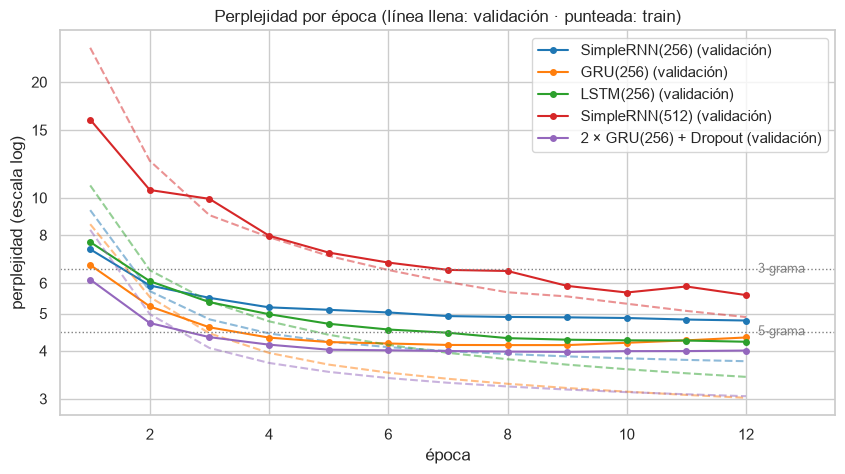

In [23]:
fig, ax = plt.subplots(figsize=(10, 5))
colores = sns.color_palette('tab10', len(resultados))
for (nombre, r), color in zip(resultados.items(), colores):
    ppl = np.array(r['cb'].history_ppl)
    epocas = np.arange(1, len(ppl) + 1)
    ax.plot(epocas, ppl[:, 1], '-o', color=color, label=f'{nombre} (validación)', ms=4)
    ax.plot(epocas, ppl[:, 0], '--', color=color, alpha=0.5)
for nombre in ('3-grama', '5-grama'):
    ax.axhline(referencias[nombre], color='gray', ls=':', lw=1)
    ax.text(EPOCAS + 0.2, referencias[nombre], nombre, va='center', fontsize=9, color='gray')
ax.set_yscale('log')
marcas = [3, 4, 5, 6, 8, 10, 15, 20]
ax.set_yticks(marcas, labels=[str(m) for m in marcas])
ax.minorticks_off()
ax.set(xlabel='época', ylabel='perplejidad (escala log)', xlim=(0.5, EPOCAS + 1.5),
       title='Perplejidad por época (línea llena: validación · punteada: train)')
ax.legend()
plt.show()

**Análisis**

- **Las celdas con compuertas ganan.** Con el mismo estado (256), los mismos datos y las mismas 12 épocas, la GRU (4,14) y la LSTM (4,22) quedan un 12–14 % por debajo de la SimpleRNN (4,80), y son las únicas de una capa que le ganan al 5-grama (4,48). La SimpleRNN, con 100 caracteres a la vista, predice peor que una tabla que cuenta qué sigue a los 4 caracteres anteriores. Es lo que se vio en la clase 3: en la celda de Elman el error vuelve paso a paso multiplicándose por W_hh y por la derivada de la tanh, y se desvanece, así que la red aprende bien lo inmediato y mal lo que está unos pasos atrás. La LSTM (con la memoria C) y la GRU (con la compuerta de update) tienen un camino aditivo por el que la información y el gradiente atraviesan muchos pasos, como en el *adding problem*.
- **No es cuestión de parámetros.** La `SimpleRNN(512)` tiene casi los mismos parámetros que la `LSTM(256)` y terminó **peor** que la de 256 (5,58). Arrancó muy mal (perplejidad de train de 24,6 en la primera época, contra 9,3 de la de 256) y su curva de validación sube y baja (época 11). Con el mismo *learning rate*, una matriz recurrente más grande hace más inestable el entrenamiento: es la otra cara del mismo problema, el gradiente que explota en vez de desvanecerse. Más neuronas en la celda de Elman no ayudan; las compuertas, sí.
- **GRU contra LSTM.** La GRU aprende más rápido (4,60 en la época 3, contra 5,35 de la LSTM), llega a su mejor valor en la época 9 y después **sobreajusta**: la perplejidad de train sigue bajando (3,20 → 3,02) y la de validación sube (4,14 → 4,33). El early stopping se queda con los pesos de la época 9. La LSTM converge más lento y en la época 12 todavía mejoraba, así que con más épocas quizás la alcanzaría. Como dijo la docente, a veces gana una y a veces la otra; con este presupuesto ganó la GRU, que además tiene 24 % menos parámetros (aunque en esta CPU no fue más rápida: 62 s por época contra 53).
- **Dos capas con dropout es el mejor modelo (3,97)**, un 4 % mejor que la GRU de una capa. La segunda capa recibe la secuencia de estados de la primera y puede combinar patrones más abstractos (clase 3, RNN multicapa). El dropout entre las capas frena el sobreajuste: desde la época 7 la validación se queda en ≈ 4,0, mientras que la GRU de una capa empeora. El costo: 2,6 veces los parámetros y 2,2 veces el tiempo por época (27 minutos en total).
- **La brecha con train:** al final, la perplejidad de train (el promedio de la última época) queda entre un 12 y un 23 % por debajo de la de validación. Una parte es sobreajuste y otra es que la validación es otro texto: los capítulos finales, con el canónigo, el cabrero y los sonetos. El punto 3.6 muestra dónde aparece la brecha.

### 3.6 ¿Cuánto contexto usa cada modelo?

Cada ventana se procesa desde un estado en cero: el carácter de la posición *t* se predice con *t* caracteres de contexto. Midiendo la perplejidad por posición se ve **cuánto contexto aprovecha cada arquitectura**: si la curva sigue bajando, el modelo usa información de más atrás.

Para que la comparación entre posiciones sea justa, uso ventanas de validación con **paso 10**: cada carácter aparece en 10 ventanas, una vez en cada decena de posiciones (por ejemplo, en las posiciones 7, 17, …, 97). Así cada decena promedia exactamente los mismos caracteres y lo único que cambia es cuánto contexto hay. Con los bloques de paso 100, cada posición promedia otros 990 caracteres y la curva sale ruidosa. Para el mejor modelo hago la misma cuenta sobre un tramo de train del mismo tamaño, texto que ya vio al entrenar.

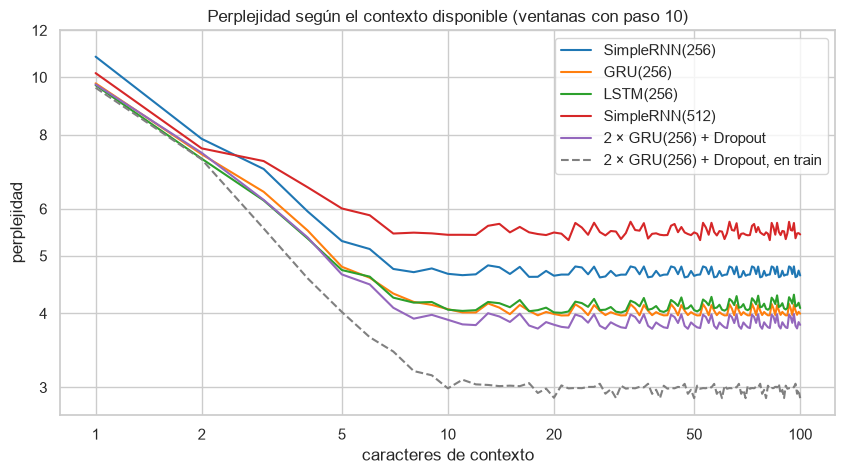

,1,2–5,6–10,11–20,21–50,51–100
SimpleRNN(256),10.83,6.45,4.80,4.69,4.69,4.69
GRU(256),9.77,5.95,4.25,4.04,4.03,4.03
LSTM(256),9.70,5.81,4.25,4.09,4.10,4.14
SimpleRNN(512),10.16,6.81,5.53,5.50,5.50,5.50
2 × GRU(256) + Dropout,9.73,5.83,4.07,3.87,3.86,3.86
"2 × GRU(256) + Dropout, en train",9.60,5.22,3.28,3.01,2.98,2.98


In [24]:
def entropia_por_posicion(model, X_, y_):
    """Entropía cruzada media (nats) en cada posición de las ventanas: con 1, 2, …, 100 caracteres de contexto."""
    probs = model.predict(X_, batch_size=1024, verbose=0)
    p_target = np.take_along_axis(probs, y_[..., None], axis=-1)[..., 0]  # (ventanas, 100)
    return -np.log(p_target).mean(axis=0)


X_val10, y_val10 = ventanas(val_text, max_context_size, 10)  # paso 10: cada carácter, una vez por decena
posiciones = pd.RangeIndex(1, max_context_size + 1, name='caracteres de contexto')
por_posicion = pd.DataFrame({nombre: entropia_por_posicion(r['model'], X_val10, y_val10)
                             for nombre, r in resultados.items()}, index=posiciones)
# Un tramo de train del mismo tamaño: ventanas consecutivas (paso 10) desde la mitad del train.
tramo = slice(len(X) // 2, len(X) // 2 + len(X_val10))
por_posicion[f'{mejor_nombre}, en train'] = entropia_por_posicion(model, X[tramo], y[tramo])

fig, ax = plt.subplots(figsize=(10, 5))
for (nombre, columna), color in zip(por_posicion.items(), [*colores, 'gray']):
    ax.plot(posiciones, np.exp(columna), '--' if 'train' in nombre else '-', color=color, label=nombre)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xticks([1, 2, 5, 10, 20, 50, 100], labels=['1', '2', '5', '10', '20', '50', '100'])
ax.set_yticks([3, 4, 5, 6, 8, 10, 12], labels=['3', '4', '5', '6', '8', '10', '12'])
ax.minorticks_off()
ax.set(xlabel='caracteres de contexto', ylabel='perplejidad', title='Perplejidad según el contexto disponible (ventanas con paso 10)')
ax.legend()
plt.show()

# Perplejidad por tramos de contexto (exponencial de la entropía cruzada media del tramo).
tramos = pd.cut(posiciones, [0, 1, 5, 10, 20, 50, 100], labels=['1', '2–5', '6–10', '11–20', '21–50', '51–100'])
np.exp(por_posicion.groupby(tramos, observed=True).mean()).T.round(2)

**Análisis**

- **Casi toda la ganancia está en los primeros 10 caracteres.** Con un solo carácter de contexto, todos los modelos están cerca de 10, apenas peor que el 2-grama (9,16); con 6 a 10 caracteres ya bajan a 4,1–5,5. Es la información de la palabra en curso: después de "caball", la letra siguiente es casi segura.
- **Desde los ~20 caracteres ningún modelo mejora.** Las curvas son planas de 20 a 100: con 51–100 caracteres de contexto la perplejidad es la misma que con 11–20 (en la LSTM, apenas peor). Lo que usan es la palabra en curso y la anterior, unas 2 o 3 palabras. El contexto de 100 de la plantilla alcanza de sobra: alargarlo no mejoraría estos modelos.
- **Las compuertas ganan en todas las posiciones, y un poco más con más contexto.** La GRU queda un 10 % por debajo de la SimpleRNN(256) con un carácter, un 12 % con 6–10 y un 14 % desde los 11. Entre los tramos 6–10 y 11–20, la SimpleRNN mejora un 2 % y las de compuertas un 4–5 %: aprovechan la palabra anterior, a unos 6–15 pasos, y la Elman casi no. La ventaja de las compuertas no es solo la "memoria de largo plazo" (acá casi no se usa más allá de 20 caracteres): también aprenden mejor las dependencias de pocos pasos, porque en cada carácter deciden qué conservar y qué borrar del estado (por ejemplo, olvidar la palabra anterior cuando llega un espacio) en vez de mezclar todo con una sola matriz.
- **La brecha con train aparece con el contexto.** En el mejor modelo, train y validación dan casi lo mismo con un carácter (9,60 y 9,73: las estadísticas de pares de letras son las mismas en todo el libro), pero desde los 10 caracteres train baja a ≈ 3,0 y validación se queda en ≈ 3,9. Con más contexto el modelo usa palabras y frases concretas del texto de entrenamiento, que se repiten menos en los capítulos de validación: eso es lo que sobreajusta.
- El serrucho de período 10 en las curvas se debe al paso de las ventanas: cada posición dentro de una decena ve un décimo distinto del texto. Por eso la tabla agrupa por tramos.

### 3.7 Experimentos descartados

Antes de armar la comparación hice pruebas con scripts aparte, con el mismo preprocesamiento (paso 10, contexto 100). Son corridas reales; no dejo el código en el notebook para no duplicarlo ni sumar media hora de cómputo, como permitió la docente.

**Learning rate y batch.** `LSTM(256)` (y `SimpleRNN(256)` en las dos últimas filas), 4 épocas, `rmsprop`:

| Celda | Learning rate | Batch | Perplejidad de validación en la época 4 | s por época |
|---|---|---|---|---|
| LSTM | 0,001 (el default de `rmsprop`) | 512 | 7,69 | 55 |
| LSTM | 0,002 | 512 | 6,71 | 49 |
| LSTM | 0,003 | 512 | 5,61 | 47 |
| LSTM | 0,005 | 512 | 5,08 | 50 |
| LSTM | 0,001 | 256 | 6,40 | 53 |
| LSTM | **0,003** | **256** | **4,62** | 53 |
| LSTM | 0,005 | 256 | 4,33 | 58 |
| SimpleRNN | **0,003** | **256** | **5,09** | 23 |
| SimpleRNN | 0,005 | 256 | 5,20 | 25 |

- Con el *learning rate* por defecto y batch de 512, después de 4 épocas la LSTM seguía en 7,7, peor que un 3-grama. El cuello de botella era la **cantidad de actualizaciones**: con batch de 512 una época son solo 174 pasos de gradiente. Con 256 son el doble y la época tarda casi lo mismo (la CPU no aprovecha mejor el batch más grande); un *learning rate* más alto hace que cada paso avance más.
- 0,005 fue un poco mejor para la LSTM pero peor para la SimpleRNN. Uso **0,003 para todas**, un valor común que no favorece a ninguna arquitectura.
- Una prueba de 3 épocas de la `SimpleRNN(512)` con 0,003 ya mostraba el arranque lento (perplejidad de validación 21,7 → 10,6 → 7,8, contra 7,2 → 5,8 → 5,4 de la de 256). La dejé así en la comparación para no cambiarle el *learning rate* a un solo modelo.

**Velocidad** (caracteres por segundo al entrenar, medido con lotes sintéticos de 100 pasos):

| Prueba | Resultado | Decisión |
|---|---|---|
| Paso 1 en vez de 10 | `LSTM(256)`: ~176.000 caracteres/s → ~8,5 min por época | Paso 10 (punto 2.6) |
| `jit_compile=True` (XLA) en `LSTM(256)`, batch 512 | 124.000 contra 190.000 caracteres/s sin XLA | Más lento en esta CPU: sin XLA |
| `recurrent_dropout=0.1` en `LSTM(256)` | 83.000 contra 176.000 caracteres/s | Dropout como capa entre capas recurrentes |
| El modelo de la plantilla, `SimpleRNN(200)` con `dropout` y `recurrent_dropout` de 0,1 | 460.000 contra 479.000 caracteres/s sin dropout | En la SimpleRNN el costo es chico; no lo uso para comparar las celdas sin regularización |
| Entrada de la plantilla (`TimeDistributed(CategoryEncoding)`) | `predict` devuelve formas erróneas al cambiar el largo | `Embedding` identidad congelado (punto 3.1) |

### 3.8 La cuenta de la plantilla contra la simplificada

Evalúo el mejor modelo con la cuenta del callback de la plantilla (con la validación corregida): 99 prefijos por bloque, rellenados con ceros hasta 100, y el promedio de la perplejidad de cada bloque. Para separar los dos efectos que la diferencian de la simplificada, la calculo también sin relleno, a partir de una sola pasada por cada bloque (en una red recurrente, la salida en la posición *t* ya es la predicción con los *t* caracteres anteriores).

In [25]:
print('Mejor modelo:', mejor_nombre)


def perplejidad_plantilla(model, secuencias, lote=4096):
    """La cuenta de PplCallback de la plantilla: cada prefijo seq[:i], rellenado con 0 hasta 100, predice seq[i];
    después se promedia la perplejidad de cada secuencia."""
    entradas = [seq[:i] for seq in secuencias for i in range(1, len(seq))]
    targets = np.array([seq[i] for seq in secuencias for i in range(1, len(seq))])
    padded = pad_sequences(entradas, maxlen=max_context_size, padding='pre')
    p = np.concatenate([model.predict(padded[i:i + lote], batch_size=BATCH, verbose=0)[:, -1, :]
                        for i in range(0, len(padded), lote)])
    logp = np.log(p[np.arange(len(targets)), targets]).reshape(len(secuencias), -1)
    return np.mean(np.exp(-logp.mean(axis=1)))


t0 = time.perf_counter()
ppl_template = perplejidad_plantilla(model, tokenized_sentences_val)
t_template = time.perf_counter() - t0

bloques = np.array(tokenized_sentences_val)
t0 = time.perf_counter()
probs = model.predict(bloques[:, :-1], batch_size=BATCH, verbose=0)
logp = np.log(np.take_along_axis(probs, bloques[:, 1:, None], axis=-1)[..., 0])
t_pasada = time.perf_counter() - t0

pd.DataFrame({
    'cuenta': ['plantilla: prefijos rellenados con 0, promedio de perplejidades por bloque',
               'plantilla sin relleno: una pasada por bloque, promedio por bloque',
               'simplificada: exp(entropía cruzada media)'],
    'perplejidad': [ppl_template, np.mean(np.exp(-logp.mean(axis=1))), np.exp(-logp.mean())],
    'tiempo (s)': [t_template, t_pasada, t_pasada],
}).set_index('cuenta').round(3)

Mejor modelo: 2 × GRU(256) + Dropout


,perplejidad,tiempo (s)
cuenta,,
"plantilla: prefijos rellenados con 0, promedio de perplejidades por bloque",4.406,49.209
"plantilla sin relleno: una pasada por bloque, promedio por bloque",4.136,0.618
simplificada: exp(entropía cruzada media),3.980,0.618


**Análisis**

- **El relleno con ceros empeora la cuenta, de 4,14 a 4,41.** Con los prefijos cortos el modelo ve hasta 99 saltos de línea seguidos antes del texto, algo que nunca vio al entrenar, y arranca desde un estado raro. Por eso tampoco relleno al generar.
- **Promediar la perplejidad de cada bloque da más que la perplejidad de todo el texto** (4,14 contra 3,98). La perplejidad es un promedio **geométrico** (lo advierte la slide 16 de la clase 4); al promediar la de cada bloque, los bloques difíciles pesan más: por la desigualdad de Jensen, el promedio de las exponenciales es mayor que la exponencial del promedio. La simplificada es la definición estándar, la exponencial de la entropía cruzada media de todos los caracteres. (Durante el entrenamiento daba 3,974 y no 3,980 porque los bloques de `X_val` predicen 100 caracteres y estos, 99.)
- **El costo:** la cuenta de la plantilla tardó 49 s por evaluación, más de un tercio de una época de la red de dos capas (134 s); la simplificada, 0,6 s. Con la validación mal armada de la plantilla (485.181 predicciones en vez de 98.109) habría tardado unas cinco veces más.
- Las diferencias son de la forma de contar, no del modelo. Para decidir cuándo cortar el entrenamiento alcanza con la simplificada, que además es casi gratis.

## 4. Generación de secuencias

Uso el mejor modelo de la comparación (`model`).

### 4.1 Predicción del próximo carácter (Gradio)

La celda de Gradio de la plantilla instala la librería con `pip` y `launch(debug=True)` bloquea el notebook hasta que se cierra la interfaz, así que queda detrás de una bandera para que el notebook corra de punta a punta. Para probarla, poner `USAR_GRADIO = True`.

In [26]:
USAR_GRADIO = False  # True para abrir la interfaz (instala gradio y bloquea esta celda hasta cerrarla)

if USAR_GRADIO:
    %pip install -q gradio
    import gradio as gr

    def model_response(human_text):
        # agrega el carácter más probable al texto ingresado
        return generate_seq(model, human_text, max_length=max_context_size, n_words=1)

    gr.Interface(fn=model_response, inputs=['textbox'], outputs='text').launch(debug=True)

### 4.2 Las funciones de la plantilla, adaptadas

- **`generate_seq` (greedy search):** en cada paso agrega el carácter más probable. Igual que en la plantilla, pero sin relleno: le paso los últimos `max_context_size` caracteres tal cual.
- **`beam_search`:** mantiene `num_beams` secuencias y en cada paso se queda con `num_beams` de todas sus continuaciones posibles, según la **probabilidad conjunta** (la suma de los log de las probabilidades). En modo `det` elige las más probables; en modo `sto` las **sortea** con probabilidad proporcional a `softmax(log P / temperatura)`. Es el mismo algoritmo de `select_candidates`, con cuatro cambios:
  1. predice todos los beams en **una sola llamada** a `predict` (un lote de `num_beams` secuencias), en vez de una por beam: 10 veces menos llamadas;
  2. no rellena con ceros (el 0 es el `\n`);
  3. en modo `sto` sortea **sin reposición** (`replace=False`). Con reposición, el mismo candidato puede salir varias veces y los beams se duplican; a temperatura baja, muchos pueden terminar siendo la misma secuencia;
  4. devuelve los beams ordenados de más a menos probable, con su log-probabilidad (en modo `sto` el orden del sorteo es aleatorio y el primero no era necesariamente el mejor).

Para medir lo generado, defino también la **perplejidad que el propio modelo le asigna al texto generado**, el porcentaje de **palabras que existen** en el Quijote y el porcentaje de **trigramas de palabras repetidos** (para detectar loops).

In [27]:
LARGO_GENERACION = 300  # caracteres a generar
palabras_corpus = set(palabras)


def predecir(model, secuencias):
    """Probabilidades del próximo carácter para un lote de secuencias del mismo largo (últimos 100 caracteres)."""
    return model.predict(secuencias[:, -max_context_size:], verbose=0)[:, -1, :]


def generate_seq(model, seed_text, max_length, n_words):
    """Greedy search: agrega `n_words` caracteres, en cada paso el más probable."""
    encoded = encode(seed_text)
    for _ in range(n_words):
        y_hat = np.argmax(predecir(model, encoded[None, -max_length:])[0])
        encoded = np.append(encoded, y_hat)
    return decode(encoded)


def beam_search(model, num_beams, num_words, input, temp=1, mode='det'):
    """Beam search determinista ('det') o estocástico ('sto'). Devuelve los textos y su log-probabilidad, de mayor a menor."""
    beams = encode(input)[None, :]  # al principio hay un solo beam: la semilla
    scores = np.zeros(1)            # log-probabilidad acumulada de cada beam
    for _ in range(num_words):
        candidatos = (scores[:, None] + np.log(predecir(model, beams) + 1e-10)).ravel()  # n_beams × vocab_size
        if mode == 'det':
            idx_select = np.argsort(candidatos)[::-1][:num_beams]
        elif mode == 'sto':
            idx_select = np.random.choice(len(candidatos), num_beams, replace=False, p=softmax(candidatos / temp))
        else:
            raise ValueError(f'Wrong selection mode. {mode} was given. det and sto are supported.')
        beams = np.concatenate([beams[idx_select // vocab_size], (idx_select % vocab_size)[:, None]], axis=1)
        scores = candidatos[idx_select]
    orden = np.argsort(scores)[::-1]
    return [decode(b) for b in beams[orden]], scores[orden]


def perplejidad_texto(model, semilla, generado):
    """Perplejidad que el modelo le asigna a lo generado después de la semilla (una pasada por todo el texto)."""
    tokens = encode(semilla + generado)
    probs = model.predict(tokens[None, :-1], verbose=0)[0]
    n = len(encode(generado))
    return np.exp(-np.log(probs[np.arange(len(tokens) - 1), tokens[1:]])[-n:].mean())


def metricas(model, semilla, texto):
    generado = texto[len(semilla):]
    pal = re.findall(r'\w+', generado)[:-1]  # la última puede quedar cortada
    trigramas = list(zip(pal, pal[1:], pal[2:]))
    return {'perplejidad del modelo': perplejidad_texto(model, semilla, generado),
            '% palabras reales': 100 * sum(p in palabras_corpus for p in pal) / max(len(pal), 1),
            '% trigramas repetidos': 100 * (1 - len(set(trigramas)) / max(len(trigramas), 1))}


def mostrar(semilla, texto, ancho=110):
    """Imprime la semilla entre corchetes y lo generado, respetando los saltos de párrafo."""
    for linea in f'[{semilla}]{texto[len(semilla):]}'.split('\n'):
        print(textwrap.fill(linea, ancho, subsequent_indent='  '))


SEMILLAS = [
    'en un lugar de la mancha, de cuyo nombre no quiero acordarme,',
    '—calla, sancho —dijo don quijote—, que',
    'y así, el valeroso caballero',
]
generaciones = []  # (estrategia, semilla, texto)

### 4.3 Greedy search

In [28]:
for semilla in SEMILLAS:
    texto = generate_seq(model, semilla, max_length=max_context_size, n_words=LARGO_GENERACION)
    generaciones.append(('greedy', semilla, texto))
    mostrar(semilla, texto)
    print()

[en un lugar de la mancha, de cuyo nombre no quiero acordarme,] porque no se le había de ser por allí a su
  amo, y así, con esto en el corral de los caballeros andantes que en el cuerpo me ha de ser por allí a su
  amo, y así, con esto en el corral de los caballeros andantes que en el cuerpo me ha de ser por allí a su
  amo, y así, con esto en el corral de los cabal



[—calla, sancho —dijo don quijote—, que] no se le había de ser por alguna cosa que lo era de los caballeros
  andantes que en el cuerpo me ha de ser por allí a su amo, y así, con esto en el corral de los caballeros
  andantes que en el cuerpo me ha de ser por allí a su amo, y así, con esto en el corral de los caballeros
  andantes que en el cue



[y así, el valeroso caballero] de los caballeros andantes que en el cuerpo me ha de ser por allí a su amo, y
  así, con esto en el corral de los caballeros andantes que en el cuerpo me ha de ser por allí a su amo, y
  así, con esto en el corral de los caballeros andantes que en el cuerpo me ha de ser por allí a su amo, y
  así, con es



**Análisis**

- **Las tres semillas terminan en el mismo loop:** "…que en el cuerpo me ha de ser por allí a su amo, y así, con esto en el corral de los caballeros andantes…", que se repite cada 105 caracteres. Cada una continúa su semilla durante unas palabras ("porque no se le había de ser…", "no se le había de ser por alguna cosa…") y en menos de 100 caracteres cae en el mismo ciclo, un **atractor** del modelo. Es lo que mostró la docente con el modelo de Borges en la clase 4 ("de la casa de la casa…"): greedy es determinista, y cuando la frase más probable llena el contexto, el carácter más probable es el que la repite.
- **Las palabras y la gramática local están bien:** todas las palabras existen y los fragmentos suenan a Cervantes ("me ha de ser", "su amo", "y así, con esto", "los caballeros andantes"). Lo que falta es coherencia: no cuenta nada.
- **No recita el libro:** la primera semilla es el comienzo del Quijote, que está en el train, y el modelo no sigue con "no ha mucho tiempo que vivía un hidalgo…". Con 650.000 parámetros no puede memorizar 891.000 caracteres: aprendió estadísticas del texto, no el texto.

### 4.4 Beam search determinista

Con 10 beams. Muestro los tres más probables de cada semilla, con su log-probabilidad.

In [29]:
for semilla in SEMILLAS:
    textos, scores = beam_search(model, num_beams=10, num_words=LARGO_GENERACION, input=semilla, mode='det')
    generaciones.append(('beam det', semilla, textos[0]))
    for k in range(3):
        print(f'beam {k + 1} · log P = {scores[k]:.1f}')
        mostrar(semilla, textos[k])
    print('─' * 110)

beam 1 · log P = -115.4
[en un lugar de la mancha, de cuyo nombre no quiero acordarme,] porque no todas estas razones que todos los
  caballeros andantes de los caballeros andantes, que todos los caballeros andantes de los caballeros
  andantes, que todos los caballeros andantes de los caballeros andantes, que todos los caballeros andantes de
  los caballeros andantes, que todos los caballe
beam 2 · log P = -115.6
[en un lugar de la mancha, de cuyo nombre no quiero acordarme,] porque no todas estas razones que todos los
  caballeros andantes de los caballeros andantes, que todos los caballeros andantes de los caballeros
  andantes, que todos los caballeros andantes de los caballeros andantes, que todos los caballeros andantes de
  los caballeros andantes, donde se había de ser
beam 3 · log P = -115.8
[en un lugar de la mancha, de cuyo nombre no quiero acordarme,] porque no todas estas razones que todos los
  caballeros andantes de los caballeros andantes, que todos los caballeros andan

beam 1 · log P = -110.5
[—calla, sancho —dijo don quijote—, que], con todo eso —respondió don quijote—, porque no todas estas razones
  que todos los caballeros andantes de los caballeros andantes, que todos los caballeros andantes de los
  caballeros andantes, que todos los caballeros andantes de los caballeros andantes, que todos los caballeros
  andantes de los cab
beam 2 · log P = -110.6
[—calla, sancho —dijo don quijote—, que], con todo eso —respondió don quijote—, porque no todas estas razones
  que todos los caballeros andantes de los caballeros andantes, que todos los caballeros andantes de los
  caballeros andantes, que todos los caballeros andantes de los caballeros andantes, que todos los caballeros
  andantes, que todos
beam 3 · log P = -110.7
[—calla, sancho —dijo don quijote—, que], con todo eso —respondió don quijote—, porque no todas estas razones
  que todos los caballeros andantes de los caballeros andantes, que todos los caballeros andantes de los
  caballeros andant

beam 1 · log P = -112.9
[y así, el valeroso caballero] de los caballeros andantes, que todos los caballeros andantes de los caballeros
  andantes, que todos los caballeros andantes de los caballeros andantes, que todos los caballeros andantes de
  los caballeros andantes, que todos los caballeros andantes de los caballeros andantes, que todos los
  caballero
beam 2 · log P = -113.7
[y así, el valeroso caballero] de los caballeros andantes, que todos los caballeros andantes de los caballeros
  andantes, que todos los caballeros andantes de los caballeros andantes, que todos los caballeros andantes de
  los caballeros andantes, que todos los caballeros andantes de los caballeros andantes, que todos los
  trabajos
beam 3 · log P = -114.7
[y así, el valeroso caballero] de los caballeros andantes, que todos los caballeros andantes de los caballeros
  andantes, que todos los caballeros andantes de los caballeros andantes, que todos los caballeros andantes de
  los caballeros andantes, que to

**Análisis**

- **Más probable no es mejor.** Beam search encuentra secuencias más probables que greedy (log P de −110 a −115 en 300 caracteres: una perplejidad de 1,46, contra 1,85 del greedy, en la tabla del punto 4.7), y las más probables son las más repetitivas: "que todos los caballeros andantes de los caballeros andantes", un loop de ~60 caracteres, más corto que el del greedy. Maximizar la probabilidad conjunta premia las frases de palabras frecuentes que se predicen a sí mismas. Beam search sirve cuando hay una respuesta "correcta" (por ejemplo, al traducir), no para escribir texto variado.
- **Los beams casi no difieren:** los tres mejores comparten todo menos los últimos caracteres. Beam search mantiene alternativas, pero todas salen del mismo tronco y terminan en el mismo loop.
- **Lo que sí aprendió:** la estructura de los diálogos. Con la semilla de don Quijote a Sancho, sigue con ", con todo eso —respondió don quijote—," con las rayas en su lugar.
- Igual que greedy, es determinista: siempre devuelve lo mismo.

### 4.5 Beam search estocástico: el efecto de la temperatura

Con 10 beams y temperaturas 0,5, 1 y 1,5. Muestro el beam más probable de cada combinación.

In [30]:
TEMPERATURAS = [0.5, 1.0, 1.5]
np.random.seed(0)  # el muestreo usa np.random
for semilla in SEMILLAS:
    for temp in TEMPERATURAS:
        textos, scores = beam_search(model, num_beams=10, num_words=LARGO_GENERACION, input=semilla, temp=temp, mode='sto')
        generaciones.append((f'beam sto T={temp}', semilla, textos[0]))
        print(f'temperatura {temp} · log P = {scores[0]:.1f}')
        mostrar(semilla, textos[0])
        print()
    print('─' * 110)

temperatura 0.5 · log P = -116.6
[en un lugar de la mancha, de cuyo nombre no quiero acordarme,] porque no me contenía en todos los caballeros
  andantes, que todos los cristianos, que todos los caballeros andantes, que todos los caballeros andantes que
  todos los caballeros andantes.
— no sé qué es lo que se llaman —respondió don quijote—, porque no tengo dicho, señor mío —respondió don
  quijote—



temperatura 1.0 · log P = -156.7
[en un lugar de la mancha, de cuyo nombre no quiero acordarme,] porque no se le respondió don quijote—, porque
  no todos los caballeros andantes que no era señora mía, que no todas las cosas de los cabellos, que no tiene
  por lo menos, sin que no estaba con todo esto, cuanto más, que no tiene por lo menos, con todo esto, y, como
  todos los demás nos hace más de ca



temperatura 1.5 · log P = -176.2
[en un lugar de la mancha, de cuyo nombre no quiero acordarme,] porque no se le contenía el rey respondió don
  quijote—, que todos entre otras semejantes, con todo esto, que por no saber lo que él era con lo que se
  contenía en todo el mundo, que tanto más, que no se le había de llevar a todos estos dos los demás señoras,
  con lo que tengo de estar en todo lo que

──────────────────────────────────────────────────────────────────────────────────────────────────────────────


temperatura 0.5 · log P = -120.3
[—calla, sancho —dijo don quijote—, que], con todo esto, don quijote de los caballeros andantes de los
  caballeros andantes, que todos los trabajos que todos los caballeros andantes, y así, con todo esto, don
  fernando, con todo esto, por lo menos, con todo esto, con todo esto, con todo esto, cuanto más, que todo lo
  cual respondió don quijo



temperatura 1.0 · log P = -149.7
[—calla, sancho —dijo don quijote—, que] todo esto era lo que todos los de los caballeros andantes, con estos
  pastores, con todo esto, con todo esto, con estos tornes, como si no, por lo menos, en todo esto, con todo
  esto, con todo esto, el cual, volvió a contenía en lo que quiere decir que no había de llevar a todos los
  caballeros andant



temperatura 1.5 · log P = -152.1
[—calla, sancho —dijo don quijote—, que] no tocaré anselmo, porque no se le respondió don quijote—, porque no
  es menester que no tengo de segundo de lo que tanto más en esto don quijote—, porque, con todo eso, se lo
  consintió don quijote—, porque, sancho —respondió don quijote—, pero no sé qué quien se le habían de
  parecerle que, sin duda

──────────────────────────────────────────────────────────────────────────────────────────────────────────────


temperatura 0.5 · log P = -127.6
[y así, el valeroso caballero] de los caballeros andantes, porque no todas las cosas de los caballeros
  andantes, que no tenían por lo menos, con todo esto, con todo esto, con todo esto, con todo esto, con todo
  esto, respondió el cura—, que todo esto esto, porque no se le respondió don quijote—, porque no tengo dicho
  —respondió d



temperatura 1.0 · log P = -139.8
[y así, el valeroso caballero] don quijote—; porque no tengo dicho, sancho —dijo don quijote—, que todo esto
  me volvió a contenía el rostro de los caballeros andantes que él era su escudero, que todos los caballeros
  andantes que no tenían con el principio de los caballeros andantes, porque no tenían con su rostro, porque
  no se l



temperatura 1.5 · log P = -165.6
[y así, el valeroso caballero], porque no tenían con el rostro con el cuerpo.
— no sé que no es bien —dijo don quijote—, porque no se podría ser —respondió don quijote—, que no con todo
  esto, sino por lo menos, y no tienen ponerse en esto en el estremo don quijote, con esto, según lo que tomó
  luego, porque no son tan buenos que

──────────────────────────────────────────────────────────────────────────────────────────────────────────────


**Análisis**

- **La temperatura rompe los loops.** Los trigramas de palabras repetidos bajan de 68 % (determinista) a 25 % con T = 0,5, 11 % con T = 1 y 3 % con T = 1,5 (tabla del punto 4.7). Con T = 0,5 todavía hay loops cortos ("con todo esto, con todo esto, con todo esto"); al subir la temperatura aparecen otros personajes (el cura, don Fernando, Anselmo) y hasta un párrafo nuevo con una intervención de diálogo ("— no sé que no es bien —dijo don quijote—").
- **Pero el texto sigue siendo "demasiado probable".** La perplejidad que el modelo le asigna a lo generado va de 1,5 a 1,7, muy por debajo de la del texto real (≈ 4), y prácticamente todas las palabras existen. Es por cómo funciona: con 10 beams, la temperatura divide la log-probabilidad **acumulada** de cada secuencia, así que el sorteo sigue favoreciendo a las secuencias más probables, y al final muestro la mejor de las 10. La temperatura cambia *cuáles* frases frecuentes se combinan, pero el texto no sale de ellas: "con todo esto", "respondió don quijote", "los caballeros andantes", "por lo menos".
- **Coherencia contra diversidad:** a T = 0,5 el texto se parece al del determinista; a T = 1,5 es más variado y sigue siendo gramatical en tramos cortos ("que no se le había de llevar a todos estos dos los demás señoras"), pero sin hilo. Para ver el efecto clásico de la temperatura hay que sacar la búsqueda (punto siguiente).

### 4.6 Muestreo con un solo beam

Con `num_beams=1` y `mode='sto'`, `beam_search` es el **muestreo con temperatura** de la clase 4: en cada paso sortea el próximo carácter con probabilidad `softmax(log P / T)`. Con un solo beam, la log-probabilidad acumulada es la misma para todos los candidatos y se cancela en la softmax. Lo agrego para separar el efecto de la temperatura del de quedarse con las secuencias más probables entre 10 beams.

In [31]:
np.random.seed(0)
for semilla in SEMILLAS:
    for temp in TEMPERATURAS:
        textos, scores = beam_search(model, num_beams=1, num_words=LARGO_GENERACION, input=semilla, temp=temp, mode='sto')
        generaciones.append((f'muestreo T={temp}', semilla, textos[0]))
        print(f'temperatura {temp} · log P = {scores[0]:.1f}')
        mostrar(semilla, textos[0])
        print()
    print('─' * 110)

temperatura 0.5 · log P = -213.4
[en un lugar de la mancha, de cuyo nombre no quiero acordarme,] que no tenían a notorio de los caballos, se le
  había de poner en todos nos entras con estos remos acontecimientos, que todos con estos pasanos, no sólo no
  tengo de saber con ellos en todos los que allí en la risa alguna, en todo esto, el cual se había escrito de
  los calzones, y con ella que en esto



temperatura 1.0 · log P = -347.4
[en un lugar de la mancha, de cuyo nombre no quiero acordarme,] siguielman.
»—digo el cabrero—, sino que no conozca, por lo que no tomó o, que tomó un pobre, y el día: o, pedido de dos,
  contenía en lo que tantos, cuantonado, junto o no, y qué bebieras. ella era menos yo en el otro, que allí la
  plica, y no tanto pensaba que él sea, y besado tanto, cierto, lágrin



temperatura 1.5 · log P = -560.8
[en un lugar de la mancha, de cuyo nombre no quiero acordarme,] mi peja, o y conamónano—; y agomosó conozó el
  premo, tan humo bien que ningán llegában?s y mirad no el cabado, y claranes y soñora imitad a zalearbo.
—digo "invenité—,, que yo no, pueda bien quégadad que, y tras y cenmos
nací; y no rogó don floso, oyé que no tuviese sosegada, y, conallo vio que, de

──────────────────────────────────────────────────────────────────────────────────────────────────────────────


temperatura 0.5 · log P = -200.1
[—calla, sancho —dijo don quijote—, que] no tocaba al revés —dijo el cura—, que en la mesma noche sin duda,
  con tomar la sintió a camila que allí le viese lo que prometía, y, como no sabes te pone en esto, cuando el
  cura y sobresalto, y todos los caballeros andantes.
— así es —dijo sancho— que él deseaba —dijo don quijote—, y si no es cor



temperatura 1.0 · log P = -329.4
[—calla, sancho —dijo don quijote—, que] yo tengo con mucho vuestra jima de no contenía y ponrá en todo suelto
  alguno, por cizcha dorotea —dijo el buen parte. — bastos buentos y cencos, en resolución, todos, sindó al
  gigante, que eranglas, de luscinda, como ha de la verdad que, llamándose que, en tanto, que tanto más que yo
  no podían la e



temperatura 1.5 · log P = -606.2
[—calla, sancho —dijo don quijote—, que] tenían y a los querotes.men, cuál quizá no leonese—me tampño, ole
  deflicó a suposizánde— sollarlos —diju: confiderux!
«hecho?»—, lo  grado, no tómas de lopía; que no sabía esto aflor de suañar al nlrvos encamina"s del rota
  pelidibil egjutado rusca de pedirá perdobó, porque en cumpé, en señores; que

──────────────────────────────────────────────────────────────────────────────────────────────────────────────


temperatura 0.5 · log P = -209.2
[y así, el valeroso caballero] como si no tomó a un contrario de los caballos, como vio que le conventa en el
  suelo con mucha presteza que no le había de ser venir a conocido, a lo menos, embusteros, y el estraño que
  los tantos pasos en el librillo de los caballeros andantes, de sus padres no se había de ser ella por lo
  mismo ho



temperatura 1.0 · log P = -347.7
[y así, el valeroso caballero] de todo el cerco.
— no te vienes, como si lo mesmoh'—
a conocerlo, ¿qué vapo voz que me muevá, pues no llevó el lucera, pasó antes que el jume della..., estuviese
  contra luego dorotea que tocando con su amo, sin; y no había enarcado —dijo don quijo, el sintiendo lotario
  fue una como las moras de no



temperatura 1.5 · log P = -512.2
[y así, el valeroso caballero]s.
— ¿biemos, mal de vitiva aquellas haz enternientes oisfermo —redpós, ¿para mo no, procur sin poco; y, como si
  tú richo!, quiera quedó en refufito vizque,, ecláis a negatuar me quitó que la buena su otra, y luego, bien
  púsosidad:
— ya fe oír, en sito aún esto.
»insiéndome tú no,gado?
— no mo le sa

──────────────────────────────────────────────────────────────────────────────────────────────────────────────


**Análisis**

- **Ahora sí se ve el efecto de la temperatura que se vio en clase:**
  - **T = 0,5:** el texto más legible del notebook. Sin loops (0,6 % de trigramas repetidos), con 98 % de palabras reales, personajes del libro (el cura, Camila, Sancho) y diálogos bien armados: "—calla, sancho —dijo don quijote—, que no tocaba al revés —dijo el cura—, que en la mesma noche sin duda…". Hasta usa *mesma*, uno de los arcaísmos del Quijote. Tiene sentido de a tramos, pero no un hilo.
  - **T = 1:** el modelo muestrea con sus probabilidades tal cual. Aparecen palabras inventadas con forma de español (*siguielman*, *cuantonado*, *eranglas*, *lágrin*) junto a nombres del libro (Dorotea, Luscinda, Lotario) y la comilla de seguir (») al principio de un párrafo, que el Quijote usa en los relatos dentro del relato (197 párrafos empiezan así). El 87 % de las palabras existen.
  - **T = 1,5:** se desarma. Solo el 63 % de las palabras existen (*conamónano*, *zalearbo*, *confiderux*), la puntuación sale al azar (",,", "?s") y no queda ninguna frase. Es lo que advirtió la docente: con la temperatura demasiado alta, el modelo "va a comenzar a hablar cualquier cosa".
- **La perplejidad del texto generado mide qué tan predecible es.** A T = 1 es 3,1, la más cercana a la del texto real (4,0): es la única estrategia que produce texto con una variedad parecida a la del idioma. Las que maximizan la probabilidad (greedy y beam search) generan texto mucho más predecible que cualquier texto real (1,5–1,9), y por eso repiten. Que a T = 1 quede algo por debajo de la real tiene sentido: el modelo está más seguro de lo que debería, porque sobreajusta un poco (en train llega a ≈ 3,0, punto 3.6).
- **Contra el beam estocástico a la misma temperatura,** el muestreo con un beam genera texto menos probable y más variado: con 10 beams, quedarse con las secuencias más probables cancela buena parte del efecto de la temperatura.

### 4.7 Las estrategias, comparadas

Promedio de las tres semillas. Como referencia, la perplejidad del modelo en el texto real de validación es la de la tabla del punto 3.5.

In [32]:
comparacion = pd.DataFrame([{'estrategia': e, **metricas(model, s, t)} for e, s, t in generaciones])
comparacion.groupby('estrategia', sort=False).mean().round(2)

,perplejidad del modelo,% palabras reales,% trigramas repetidos
estrategia,,,
greedy,1.85,100.00,55.50
beam det,1.46,100.00,68.45
beam sto T=0.5,1.50,100.00,25.47
beam sto T=1.0,1.64,100.00,11.11
beam sto T=1.5,1.73,99.38,3.05
muestreo T=0.5,2.00,98.31,0.57
muestreo T=1.0,3.12,87.44,0.00
muestreo T=1.5,6.51,63.11,0.00


**Análisis**

- **Las estrategias van de la repetición al ruido.** De arriba a abajo de la tabla, la perplejidad del texto generado sube (de 1,46 a 6,51), los loops desaparecen (de 68 % a 0 % de trigramas repetidos) y aparecen palabras inventadas (de 100 % a 63 % de palabras reales). En un extremo están las estrategias deterministas, con texto correcto pero circular; en el otro, el muestreo a T = 1,5, variado pero sin palabras.
- **El punto intermedio**, para este modelo, es el muestreo con temperatura entre 0,5 y 1, o el beam estocástico con temperatura alta: sin loops y con pocas palabras inventadas. Coincide con lo que se dijo en clase: en la práctica se muestrea y se ajusta la temperatura hasta encontrar el punto ideal.
- **El estilo del Quijote aparece en todas:** el vocabulario (*caballeros andantes*, *escudero*, *señor mío*, *por lo menos*, *con todo esto*), los arcaísmos (*mesma*, *estremo*, *della*), los personajes y los diálogos con raya y verbo de habla (*—respondió don quijote—*). El modelo aprendió muy bien la forma del texto en una ventana de pocas palabras, y nada de sentido más allá de esa ventana (punto 3.6).

## 5. Conclusiones

1. **Corpus.** La primera parte del Quijote, ≈ 1 millón de caracteres, alcanza para entrenar en CPU, en minutos, un modelo por caracteres que escribe palabras reales con el estilo del libro. Cortar el encabezado y el pie de Gutenberg, unir las líneas partidas y pasar a minúsculas dejó un vocabulario de 53 caracteres, con la puntuación y los espacios incluidos.
2. **Preprocesamiento.** Lo que más pesó fue armar bien el dataset. La plantilla tenía mal la validación (bloques de 0, 1, 2… caracteres) y su forma de armar `X` e `y` solo funciona con paso 1. El paso 10 bajó el costo 10 veces sin perder texto, y la validación contigua al final evita que se filtre texto de entrenamiento. El contexto de 100 caracteres sobra: los modelos usan unos 20.
3. **Arquitecturas.** Las compuertas importan más que los parámetros. Con el mismo estado y las mismas épocas, la GRU (4,14) y la LSTM (4,22) le ganan a la SimpleRNN (4,80), y una SimpleRNN con el doble de estado, con casi tantos parámetros como la LSTM, empeora (5,58) porque es más inestable de entrenar. El mejor modelo es el de dos capas GRU con dropout (3,97), que además sobreajusta menos. Es lo de la clase 3: el gradiente que se desvanece o explota en la celda de Elman y el camino aditivo de la LSTM y la GRU.
4. **Generación.** Las estrategias que maximizan la probabilidad (greedy y beam search determinista) caen en loops. El beam search estocástico los rompe, pero sigue recombinando frases frecuentes porque la temperatura actúa sobre la probabilidad acumulada de 10 beams. El muestreo con un solo beam muestra el efecto clásico de la temperatura: coherente a 0,5, con palabras inventadas a 1 e ilegible a 1,5. Como dijo la docente, "no esperen un ChatGPT", pero el modelo aprendió ortografía, puntuación, diálogos y el vocabulario del Quijote.

**Qué mejoraría**
- **Más datos y más cómputo:** con GPU, el libro completo (2,1 millones de caracteres) y redes más grandes (2 o 3 capas de 512) con más dropout. Con más texto, el sobreajuste baja.
- **El entrenamiento:** bajar el *learning rate* cuando la validación se estanca (`ReduceLROnPlateau`) y elegir el *learning rate* de cada celda por separado: la `SimpleRNN(512)` necesitaba uno más chico.
- **Más contexto útil:** una RNN *stateful*, que pase el estado de una ventana a la siguiente, para poder aprender dependencias de más de 100 caracteres (aunque estos modelos no usaron más de 20).
- **Las mayúsculas:** conservarlas, para que el modelo aprenda los nombres propios y el principio de las oraciones.
- **La generación:** sumarle a la temperatura top-k o top-p (clase 4), o penalizar las repeticiones en el beam search.